In [20]:
## Standard libraries
import os
import math
import numpy as np
import time

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
from matplotlib.colors import to_rgba
import seaborn as sns
sns.set()

## Progress bar
from tqdm.notebook import tqdm

<ipython-input-20-ef889392170e>:11: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('svg', 'pdf') # For export


In [21]:
import torch
print("Using torch", torch.__version__)

Using torch 2.5.1+cu121


As in every machine learning framework, PyTorch provides functions that are stochastic like generating random numbers. However, a very good practice is to setup your code to be reproducible with the exact same random numbers. This is why we set a seed below.

In [36]:
torch.manual_seed(42) # Setting the seed

#Tensors

Tensors are the PyTorch equivalent to Numpy arrays, with the addition to also have support for GPU acceleration (more on that later).

##Definition
The name “tensor” is a generalization of concepts you already know. For instance, a vector is a 1-D tensor, and a matrix a 2-D tensor. When working with neural networks, we will use tensors of various shapes and number of dimensions.

In [ ]:
  #simplest way to create a tensor:
x = torch.Tensor(2, 3, 4)
print(x)

tensor([[[1.3283e-08, 1.2812e-11, 4.3963e-05, 1.6597e-07],
         [1.6689e+22, 7.9966e+20, 1.7489e-04, 8.2189e+20],
         [2.4287e-18, 3.1360e+27, 7.0800e+31, 3.1095e-18]],

        [[2.9907e+21, 1.1626e+27, 1.6534e+19, 3.0601e+32],
         [3.3129e-18, 8.2207e+32, 1.8394e+25, 6.1963e-04],
         [4.1185e-11, 1.4580e-19, 7.1429e+31, 1.5766e-19]]])


The function torch.Tensor allocates memory for the desired tensor, but reuses any values that have already been in the memory. To directly assign values to the tensor during initialization, there are many alternatives including:

torch.zeros: Creates a tensor filled with zeros
torch.ones: Creates a tensor filled with ones
torch.rand: Creates a tensor with random values uniformly sampled between 0 and 1
torch.randn: Creates a tensor with random values sampled from a normal distribution with mean 0 and variance 1
torch.arange: Creates a tensor containing the values: N, N+1,N+2... M

torch.Tensor (input list): Creates a tensor from the list elements you provide

In [ ]:
# Create a tensor from a (nested) list
x = torch.Tensor([[1, 2], [3, 4]])
print(x)

tensor([[1., 2.],
        [3., 4.]])


In [ ]:
# Create a tensor with random values between 0 and 1 with the shape [2, 3, 4]
x = torch.rand(2, 3, 4)
print(x)

tensor([[[0.8823, 0.9150, 0.3829, 0.9593],
         [0.3904, 0.6009, 0.2566, 0.7936],
         [0.9408, 0.1332, 0.9346, 0.5936]],

        [[0.8694, 0.5677, 0.7411, 0.4294],
         [0.8854, 0.5739, 0.2666, 0.6274],
         [0.2696, 0.4414, 0.2969, 0.8317]]])


You can obtain the shape of a tensor in the same way as in numpy (x.shape), or using the .size method:

In [ ]:
shape = x.shape
print("Shape:", x.shape)

size = x.size()
print("Size:", size)

dim1, dim2, dim3 = x.size()
print("Size:", dim1, dim2, dim3)

Shape: torch.Size([2, 3, 4])
Size: torch.Size([2, 3, 4])
Size: 2 3 4


#Tensor to Numpy, and Numpy to Tensor

Tensors can be converted to numpy arrays, and numpy arrays back to tensors. To transform a numpy array into a tensor, we can use the function torch.from_numpy:



Tensors can be converted to numpy arrays, and numpy arrays back to tensors. To transform a numpy array into a tensor, we can use the function torch.from_numpy:

In [ ]:
np_arr = np.array([[1, 2], [3, 4]])
tensor = torch.from_numpy(np_arr)

print("Numpy array:", np_arr)
print("PyTorch tensor:", tensor)

Numpy array: [[1 2]
 [3 4]]
PyTorch tensor: tensor([[1, 2],
        [3, 4]])


To transform a PyTorch tensor back to a numpy array, we can use the function .numpy() on tensors:

In [ ]:
tensor = torch.arange(4)
np_arr = tensor.numpy()

print("PyTorch tensor:", tensor)
print("Numpy array:", np_arr)

PyTorch tensor: tensor([0, 1, 2, 3])
Numpy array: [0 1 2 3]


The conversion of tensors to numpy require the tensor to be on the CPU, and not the GPU (more on GPU support in a later section). In case you have a tensor on GPU, you need to call .cpu() on the tensor beforehand. Hence, you get a line like np_arr = tensor.cpu().numpy().



#OPERATIONS
Most operations that exist in numpy, also exist in PyTorch.

###ADDING/SUMS

In [ ]:
x1 = torch.rand(2, 3)
x2 = torch.rand(2, 3)
y = x1 + x2

print("X1", x1)
print("X2", x2)
print("Y", y)

X1 tensor([[0.1053, 0.2695, 0.3588],
        [0.1994, 0.5472, 0.0062]])
X2 tensor([[0.9516, 0.0753, 0.8860],
        [0.5832, 0.3376, 0.8090]])
Y tensor([[1.0569, 0.3448, 1.2448],
        [0.7826, 0.8848, 0.8151]])


###Changing Tensor shape
Another common operation aims at changing the shape of a tensor. A tensor of size (2,3) can be re-organized to any other shape with the same number of elements (e.g. a tensor of size (6), or (3,2), …). In PyTorch, this operation is called view:

In [ ]:
x = torch.arange(6)
print("X", x)

X tensor([0, 1, 2, 3, 4, 5])


In [ ]:
#without changing the original tensor:
x2 = x.view(2, 3)
print("X", x2)

X tensor([[0, 1, 2],
        [3, 4, 5]])


In [ ]:
#changing the original tensor:

x = x.view(2, 3)
print("X", x)

X tensor([[0, 1, 2],
        [3, 4, 5]])


In [ ]:
x = x.permute(1, 0) # Swapping dimension 0 and 1
print("X", x)

X tensor([[0, 1, 2],
        [3, 4, 5]])


###Matrix Products
Quite often, we have an input vector , which is transformed using a learned weight matrix . There are multiple ways and functions to perform matrix multiplication:

torch.matmul: Performs the matrix product over two tensors, where the specific behavior depends on the dimensions. If both inputs are matrices (2-dimensional tensors), it performs the standard matrix product. For higher dimensional inputs, the function supports broadcasting (for details see the documentation). Can also be written as a @ b, similar to numpy.
torch.mm: Performs the matrix product over two matrices, but doesn’t support broadcasting (see documentation)
torch.bmm: Performs the matrix product with a support batch dimension. If the first tensor T is of shape (b x n x m), and the second tensor  R(bxmxp), the output O is of shape (bxnxp), and has been calculated by performing  matrix multiplications of the submatrices of  and :
torch.einsum: Performs matrix multiplications and more (i.e. sums of products) using the Einstein summation convention. Explanation of the Einstein sum can be found in assignment 1.


In [ ]:
x = torch.arange(6)
x = x.view(2, 3)
print("X", x)

X tensor([[0, 1, 2],
        [3, 4, 5]])


In [ ]:
W = torch.arange(9).view(3, 3) # We can also stack multiple operations in a single line
print("W", W)

W tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]])


In [ ]:
h = torch.matmul(x, W) # Verify the result by calculating it by hand too!
print("h", h)

h tensor([[15, 18, 21],
        [42, 54, 66]])


###Indexing
We often have the situation where we need to select a part of a tensor. Indexing works just like in numpy, so let’s try it:

In [ ]:
x = torch.arange(12).view(3, 4)
print("X", x)

In [ ]:
print(x[:, 1])   # Second column

tensor([1, 4])


In [ ]:
print(x[0])      # First row

In [ ]:
print(x[:2, -1]) # First two rows, last column


tensor([2, 5])


In [ ]:
print(x[1:3, :]) # Middle two rows

tensor([[3, 4, 5]])


#Learning by example: Continuous XOR

If we want to build a neural network in PyTorch, we could specify all our parameters (weight matrices, bias vectors) using Tensors (with requires_grad=True), ask PyTorch to calculate the gradients and then adjust the parameters. But things can quickly get cumbersome if we have a lot of parameters. In PyTorch, there is a package called torch.nn that makes building neural networks more convenient.


We will introduce the libraries and all additional parts you might need to train a neural network in PyTorch, using a simple example classifier on a simple yet well known example: XOR. Given two binary inputs and, the label to predict is if either or is while the other is, or the label is in all other cases. The example became famous by the fact that a single neuron, i.e. a linear classifier, cannot learn this simple function. Hence, we will learn how to build a small neural network that can learn this function. To make it a little bit more interesting, we move the XOR into continuous space and introduce some gaussian noise on the binary inputs. Our desired separation of an XOR dataset could look as follows:




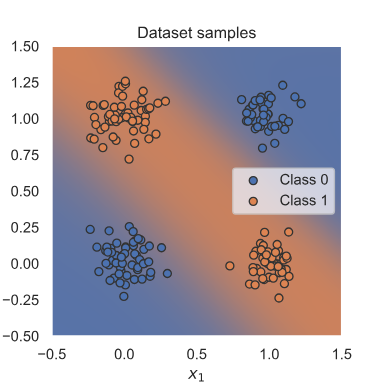

In [23]:
##The model
The package "torch.nn" defines a series of useful clases like linear networks layers, activation functions, loss functions, etc.

SyntaxError: invalid syntax (<ipython-input-23-bdf23ff5f140>, line 2)

In [24]:
import torch.nn as nn

There is also torch.nn.functional which contains functions used in network layers. "torch.nn" uses a lot of functionalities from "torch.nn.functional, however it defines them as modules instead of functions.

In [25]:
import torch.nn.functional as F

##nn.Module
In Pytorch a neural network is built up out of modules and modules can contain other modules, whatsmore a neural network is considerd to be a module itself.
This is the basic template of a module:

In [26]:
class MyModule(nn.Module):

    def __init__(self):
        super().__init__()
        # Some init for my module

    def forward(self, x):
        # Function for performing the calculation of the module.
        pass

The forward function is where the computation of the module is taken place, and is executed when you call the module (nn = MyModule(); nn(x)). In the init function, we usually create the parameters of the module, using nn.Parameter, or defining other modules that are used in the forward function. The backward calculation is done automatically, but could be overwritten as well if wanted.

##Simple classifier

Now we can use the pre-defined modules in the torch.nn package and define our neural network. We will use a minimal network with an input layer, 1 hidden layer with tanh as activation functin and an output layer.

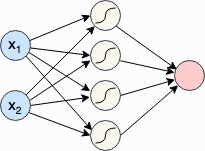

The input neurons are shown in blue, which represents the coordinates x1 and x2 of a data point. The hidden neurons include a tanh activation (represented in white circles) and the outputs (red circle). PyTorch, we can define as follows:

In [27]:
class SimpleClassifier(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_outputs):
        super().__init__()
        #Initialize the modules
        self.linear1 = nn.Linear(num_inputs, num_hidden)
        self.act_fn = nn.Tanh()
        self.linear2 = nn.Linear(num_hidden, num_outputs)


For the examples in this notebook, we will use a tiny neural network with two input neurons and four hidden neurons. As we perform binary classification, we will use a single output neuron. Note that we do not apply a sigmoid on the output yet. This is because other functions, especially the loss, are more efficient and precise to calculate on the original outputs instead of the sigmoid output. We will discuss the detailed reason later.


In [28]:
model = SimpleClassifier(num_inputs=2, num_hidden=4, num_outputs=1)
# Printing a module shows all its submodules
print(model)

SimpleClassifier(
  (linear1): Linear(in_features=2, out_features=4, bias=True)
  (act_fn): Tanh()
  (linear2): Linear(in_features=4, out_features=1, bias=True)
)


Printing the model lists all submodules it contains. The parameters of a module can be obtained by using its parameters() functions, or named_parameters() to get a name to each parameter object. For our small neural network, we have the following parameters:

In [29]:
for name, param in model.named_parameters():
    print(f"Parameter {name}, shape {param.shape}")

Parameter linear1.weight, shape torch.Size([4, 2])
Parameter linear1.bias, shape torch.Size([4])
Parameter linear2.weight, shape torch.Size([1, 4])
Parameter linear2.bias, shape torch.Size([1])


Each linear layer has a weight matrix of the shape [output, input], and a bias of the shape [output]. The tanh activation function does not have any parameters. Note that parameters are only registered for nn.Module objects that are direct object attributes, i.e. self.a = .... If you define a list of modules, the parameters of those are not registered for the outer module and can cause some issues when you try to optimize your module. There are alternatives, like nn.ModuleList, nn.ModuleDict and nn.Sequential, that allow you to have different data structures of modules. We will use them in a few later tutorials and explain them there.

##The data

PyTorch also provides a few functionalities to load the training and test data efficiently, summarized in the package torch.utils.data.

In [30]:
import torch.utils.data as data

The data package defines two classes which are the standard interface for handling data in PyTorch: data.Dataset, and data.DataLoader. The dataset class provides an uniform interface to access the training/test data, while the data loader makes sure to efficiently load and stack the data points from the dataset into batches during training.

##The dataset class

The dataset class summarizes the basic functionality of a dataset in a natural way. To define a dataset in PyTorch, we simply specify two functions: __getitem__, and __len__. The get-item function has to return the -th data point in the dataset, while the len function returns the size of the dataset. For the XOR dataset, we can define the dataset class as follows:


In [31]:
class XORDataset(data.Dataset):

    def __init__(self, size, std=0.1):
        """
        Inputs:
            size - Number of data points we want to generate
            std - Standard deviation of the noise (see generate_continuous_xor function)
        """
        super().__init__()
        self.size = size
        self.std = std
        self.generate_continuous_xor()

    def generate_continuous_xor(self):
        # Each data point in the XOR dataset has two variables, x and y, that can be either 0 or 1
        # The label is their XOR combination, i.e. 1 if only x or only y is 1 while the other is 0.
        # If x=y, the label is 0.
        data = torch.randint(low=0, high=2, size=(self.size, 2), dtype=torch.float32)
        label = (data.sum(dim=1) == 1).to(torch.long)
        # To make it slightly more challenging, we add a bit of gaussian noise to the data points.
        data += self.std * torch.randn(data.shape)

        self.data = data
        self.label = label

    def __len__(self):
        # Number of data point we have. Alternatively self.data.shape[0], or self.label.shape[0]
        return self.size

    def __getitem__(self, idx):
        # Return the idx-th data point of the dataset
        # If we have multiple things to return (data point and label), we can return them as tuple
        data_point = self.data[idx]
        data_label = self.label[idx]
        return data_point, data_label

In [ ]:
#Creating Dataset
dataset = XORDataset(size=200)
print("Size of dataset:", len(dataset))
print("Data point 0:", dataset[0])

Size of dataset: 200
Data point 0: (tensor([-0.0325,  0.9849]), tensor(1))


To better relate to the dataset, we visualize the samples below.

In [32]:
def visualize_samples(data, label):
    if isinstance(data, torch.Tensor):
        data = data.cpu().numpy()
    if isinstance(label, torch.Tensor):
        label = label.cpu().numpy()
    data_0 = data[label == 0]
    data_1 = data[label == 1]

    plt.figure(figsize =(4,4))
    plt.scatter(data_0[:,0], data_0[:,1], edgecolor ="#333", label="Class 0")
    plt.scatter(data_1[:,0], data_1[:,1], edgecolor ="#333", label="Class 1")
    plt.title("Dataset samples")
    plt.ylabel(r"$x_2$")
    plt.xlabel(r"$x_1$")
    plt.legend()


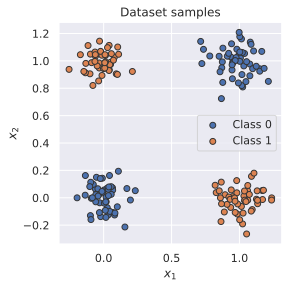

In [33]:
visualize_samples(dataset.data, dataset.label)
plt.show()

##The data loader class


In [34]:
data_loader = data.DataLoader(dataset, batch_size=8, shuffle=True)

In [37]:
#next (iter(...))catcjes tje forst batch of the data loader
#if shuffle is True, this will return a different batch everytime we run this cell
#for iterating oveer the whole dataset, we can simply use "for bach in data_loader: ..."
data_inputs, data_labels = next(iter(data_loader))

#the shape of the outpits are [batch_size, d_1, ..., d_N] where d_1, ..., d_N
#are the dimensions of the data point returned from the dataset class
print("Data inputs", data_inputs.shape, "\n", data_inputs)
print("Data labels", data_labels.shape, "\n", data_labels)

Data inputs torch.Size([8, 2]) 
 tensor([[-0.0602,  1.0340],
        [ 0.0184,  0.0045],
        [ 0.8504,  1.0336],
        [ 1.0768,  0.8912],
        [ 0.0188, -0.0296],
        [ 1.0144, -0.0634],
        [-0.0225,  1.0697],
        [ 0.0458,  0.9728]])
Data labels torch.Size([8]) 
 tensor([1, 0, 0, 0, 0, 1, 1, 1])


##Optimization
After defining the model and the dataset, it is tine to optimize with the folliwng steps:

1. Get a Batch from the data loader
2. Obtain the predictions from the model for the batch
3. Calculate the loss based on the difference between predictions and labels
4. Backpropagation: calculate the ingredients for every parameter with respect to the loss
5. Update the parameters of the model in the direction of the gradients.

### Loss modules

To calculate loss for a batch we can peform a few tensor operations. For binary classification we can use "Binary Cross Entropy (BCE)" which is defined as follows:

L(BCE) = - sum(yi log(xi)+(1 - yi)log(1 - xi))

where y are our labels, and x our predictions, both in range of [0,1]. However, PyTorch already provides a list of predefined loss functions which we can use. For BCE PyTorch already has 2 modules: nn.BCELoss(), nn.BCEWithLogisticsLoss().
-